In [ ]:
import os, shutil
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!mkdir -p /root/radiografias/
!unzip "drive/MyDrive/Datos/radiografias.zip" -d "/root/"

Archive:  drive/MyDrive/Datos/radiografias.zip
   creating: /root/radiografias/entrenamiento/
   creating: /root/radiografias/entrenamiento/neumonia/
  inflating: /root/radiografias/entrenamiento/neumonia/BACTERIA-1008087-0001.jpeg  
  inflating: /root/radiografias/entrenamiento/neumonia/BACTERIA-1025587-0001.jpeg  
  inflating: /root/radiografias/entrenamiento/neumonia/BACTERIA-1027194-0001.jpeg  
  inflating: /root/radiografias/entrenamiento/neumonia/BACTERIA-1033441-0001.jpeg  
  inflating: /root/radiografias/entrenamiento/neumonia/BACTERIA-103798-0001.jpeg  
  inflating: /root/radiografias/entrenamiento/neumonia/BACTERIA-103798-0002.jpeg  
  inflating: /root/radiografias/entrenamiento/neumonia/BACTERIA-1039608-0001.jpeg  
  inflating: /root/radiografias/entrenamiento/neumonia/BACTERIA-1040986-0001.jpeg  
  inflating: /root/radiografias/entrenamiento/neumonia/BACTERIA-1041881-0001.jpeg  
  inflating: /root/radiografias/entrenamiento/neumonia/BACTERIA-1041881-0002.jpeg  
  inflating:

In [ ]:
print('total training neumonia images:', len(os.listdir('/root/radiografias/entrenamiento/neumonia')))

total training neumonia images: 1000


In [ ]:
# Preparación de las imagenes en crudo en su representación en tensor

from keras.preprocessing.image import ImageDataGenerator

In [ ]:
train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

In [ ]:
train_generator = train_datagen.flow_from_directory(
    '/root/radiografias/entrenamiento',
    target_size=(224, 224),
    batch_size=20,
    class_mode='binary')

Found 2000 images belonging to 2 classes.


In [ ]:
validation_generator = test_datagen.flow_from_directory(
    '/root/radiografias/validacion',
    target_size=(224, 224),
    batch_size=20,
    class_mode='binary')

Found 666 images belonging to 2 classes.


In [ ]:

for data_batch, labels_batch in train_generator:
    print('data batch shape:', data_batch.shape)
    print('labels batch shape:', labels_batch.shape)
    break

data batch shape: (20, 224, 224, 3)
labels batch shape: (20,)


In [ ]:
from keras.applications import ResNet50
conv_base = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

94765736/94765736 [==============================] - 1s 0us/step


In [ ]:
conv_base.summary()

Model: "resnet50"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 conv1_pad (ZeroPadding2D)   (None, 230, 230, 3)          0         ['input_1[0][0]']             
                                                                                                  
 conv1_conv (Conv2D)         (None, 112, 112, 64)         9472      ['conv1_pad[0][0]']           
                                                                                                  
 conv1_bn (BatchNormalizati  (None, 112, 112, 64)         256       ['conv1_conv[0][0]']          
 on)                                                                                       

In [ ]:
conv_base.trainable = False
layer_to_unfreeze = ['conv5_block3_3_conv']
for layer in conv_base.layers:
    if layer.name == layer_to_unfreeze:
        layer.trainable = True

In [ ]:
from keras import models
from keras import layers

model = models.Sequential()
model.add(conv_base)
model.add(layers.Flatten())
model.add(layers.Dense(256, activation='relu'))
model.add(layers.Dense(1, activation='sigmoid'))

In [ ]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resnet50 (Functional)       (None, 7, 7, 2048)        23587712  
                                                                 
 flatten (Flatten)           (None, 100352)            0         
                                                                 
 dense (Dense)               (None, 256)               25690368  
                                                                 
 dense_1 (Dense)             (None, 1)                 257       
                                                                 
Total params: 49278337 (187.98 MB)
Trainable params: 25690625 (98.00 MB)
Non-trainable params: 23587712 (89.98 MB)
_________________________________________________________________


In [ ]:
from tensorflow.keras import optimizers

model.compile(loss='binary_crossentropy', optimizer=optimizers.RMSprop(learning_rate=1e-4), metrics=['acc'])

In [ ]:
from keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss', min_delta=0.001, patience=10, verbose=1, restore_best_weights=True)

In [ ]:
history = model.fit_generator(train_generator, steps_per_epoch=100, epochs=30, validation_data=validation_generator, validation_steps=33)

<ipython-input-16-500bbee5f71c>:1: UserWarning: `Model.fit_generator` is deprecated and will be removed in a future version. Please use `Model.fit`, which supports generators.
  history = model.fit_generator(train_generator, steps_per_epoch=100, epochs=30, validation_data=validation_generator, validation_steps=33)


Epoch 1/30
100/100 [==============================] - 46s 373ms/step - loss: 0.7270 - acc: 0.6165 - val_loss: 0.5756 - val_acc: 0.7303
Epoch 2/30
100/100 [==============================] - 35s 345ms/step - loss: 0.5424 - acc: 0.7460 - val_loss: 0.4918 - val_acc: 0.8197
Epoch 3/30
100/100 [==============================] - 37s 367ms/step - loss: 0.4773 - acc: 0.8075 - val_loss: 0.4534 - val_acc: 0.8288
Epoch 4/30
100/100 [==============================] - 38s 378ms/step - loss: 0.4372 - acc: 0.8195 - val_loss: 0.4190 - val_acc: 0.8455
Epoch 5/30
100/100 [==============================] - 35s 346ms/step - loss: 0.4158 - acc: 0.8250 - val_loss: 0.4192 - val_acc: 0.8303
Epoch 6/30
100/100 [==============================] - 35s 356ms/step - loss: 0.4066 - acc: 0.8340 - val_loss: 0.3722 - val_acc: 0.8652
Epoch 7/30
100/100 [==============================] - 37s 366ms/step - loss: 0.3860 - acc: 0.8520 - val_loss: 0.3764 - val_acc: 0.8348
Epoch 8/30
100/100 [==============================] - 3

In [ ]:
history_dict = history.history

In [ ]:
history_dict.keys()

dict_keys(['loss', 'acc', 'val_loss', 'val_acc'])

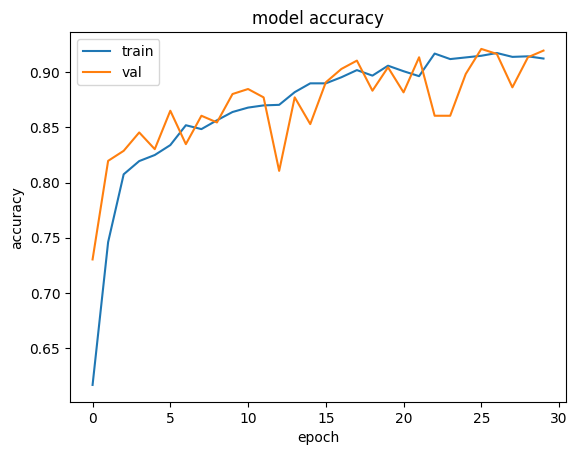

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['acc'])
plt.plot(history.history['val_acc'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

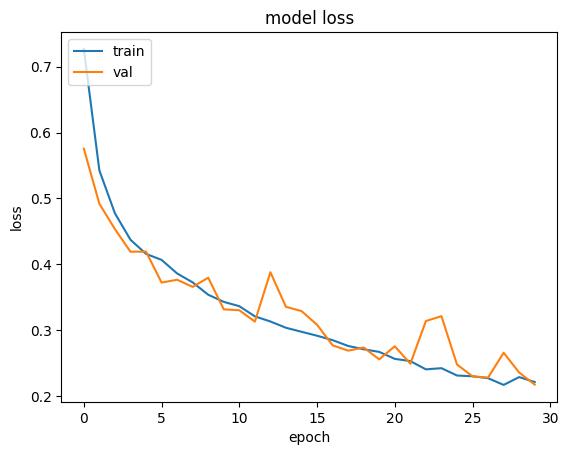

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

In [ ]:
test_generator = test_datagen.flow_from_directory(
    '/root/radiografias/test',
    target_size=(224, 224),
    batch_size=20,
    class_mode='binary')

Found 500 images belonging to 2 classes.


In [ ]:
# estimar la preción al predecir todo el dataset
scores = model.evaluate(test_generator)
print("%s: %.2f%%" % (model.metrics_names[1], scores[1]*100))

25/25 [==============================] - 6s 249ms/step - loss: 0.2390 - acc: 0.9000
acc: 90.00%
